In [7]:
import os
import time
import warnings
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")

# ============================================================
# 1. LOAD DATA
# ============================================================

DATASET_PATH = "/kaggle/input/datasets/berkanoztas/synthetic-transaction-monitoring-dataset-aml"

csv_files = [f for f in os.listdir(DATASET_PATH) if f.lower().endswith(".csv")]
csv_file = csv_files[0]

df = pd.read_csv(os.path.join(DATASET_PATH, csv_file))

print("Dataset:", csv_file)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

# ============================================================
# 2. SORT CHRONOLOGICALLY
# ============================================================

df["Timestamp"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    errors="coerce"
)

df = df.sort_values("Timestamp").reset_index(drop=True)

# ============================================================
# 3. FEATURE ENGINEERING
# ============================================================

df["Currency_Mismatch"] = (
    df["Payment_currency"] != df["Received_currency"]
).astype(int)

df["Bank_Location_Mismatch"] = (
    df["Sender_bank_location"] != df["Receiver_bank_location"]
).astype(int)

df["Same_Bank"] = (
    df["Sender_bank_location"] == df["Receiver_bank_location"]
).astype(int)

df["Amount_Log"] = np.log1p(df["Amount"])
df["Amount_Zero"] = (df["Amount"] == 0).astype(int)

df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek
df["Weekend"] = (df["DayOfWeek"] >= 5).astype(int)

# Historical transaction counts
df["Sender_Transaction_Count"] = (
    df.groupby("Sender_account").cumcount()
)

df["Receiver_Transaction_Count"] = (
    df.groupby("Receiver_account").cumcount()
)

df["Sender_Receiver_Pair_Count"] = (
    df.groupby(["Sender_account", "Receiver_account"]).cumcount()
)

# ============================================================
# 4. REMOVE LEAKAGE / IDENTIFIERS
# ============================================================

target = "Is_laundering"

drop_cols = [
    target,
    "Laundering_type",
    "Sender_account",
    "Receiver_account",
    "Date",
    "Time",
    "Timestamp"
]

X = df.drop(columns=drop_cols)
y = df[target].astype(int)

print("\nTarget distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True))

# ============================================================
# 5. CHRONOLOGICAL 70/30 TRAIN-TEST SPLIT
# ============================================================

split_index = int(len(X) * 0.70)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("\nTrain shape:", X_train.shape)
print("Test shape :", X_test.shape)

print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

# ============================================================
# 6. PREPROCESSING
# ============================================================

categorical_features = [
    "Payment_currency",
    "Received_currency",
    "Sender_bank_location",
    "Receiver_bank_location",
    "Payment_type"
]

numeric_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numeric_features
        )
    ]
)

# ============================================================
# 7. MODELS
# ============================================================

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=None,
        min_samples_leaf=2
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

# ============================================================
# 8. 5-FOLD STRATIFIED CV + SMOTE
# ============================================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for model_name, model in models.items():

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    fold_metrics = []
    total_start = time.time()

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_train, y_train), 1
    ):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        pipeline = ImbPipeline(
            steps=[
                ("preprocessor", preprocessor),
                (
                    "smote",
                    SMOTE(
                        sampling_strategy=0.1,
                        random_state=42
                    )
                ),
                ("model", model)
            ]
        )

        start = time.time()

        pipeline.fit(X_tr, y_tr)

        y_pred = pipeline.predict(X_val)
        y_prob = pipeline.predict_proba(X_val)[:, 1]

        fold_time = time.time() - start

        metrics = {
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_val, y_pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_val, y_prob),
            "PR-AUC": average_precision_score(y_val, y_prob),
            "Time": fold_time
        }

        fold_metrics.append(metrics)

        print(
            f"Fold {fold}: "
            f"Accuracy={metrics['Accuracy']:.4f}, "
            f"F1={metrics['F1']:.4f}, "
            f"PR-AUC={metrics['PR-AUC']:.4f}"
        )

    avg_metrics = pd.DataFrame(fold_metrics).mean()

    results.append({
        "Model": model_name,
        "Accuracy": avg_metrics["Accuracy"],
        "Precision": avg_metrics["Precision"],
        "Recall": avg_metrics["Recall"],
        "F1": avg_metrics["F1"],
        "ROC-AUC": avg_metrics["ROC-AUC"],
        "PR-AUC": avg_metrics["PR-AUC"],
        "CV_Time": time.time() - total_start
    })

# ============================================================
# 9. CV RESULTS
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["PR-AUC", "F1"],
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("CROSS-VALIDATION RESULTS")
print("=" * 70)

print(results_df.to_string(index=False))

winner_name = results_df.iloc[0]["Model"]

print("\nSelected model:", winner_name)

# ============================================================
# 10. TRAIN WINNING MODEL ON FULL TRAINING DATA
# ============================================================

winner_model = models[winner_name]

final_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "smote",
            SMOTE(
                sampling_strategy=0.1,
                random_state=42
            )
        ),
        ("model", winner_model)
    ]
)

print("\nTraining final model...")

train_start = time.time()

final_pipeline.fit(X_train, y_train)

training_time = time.time() - train_start

# ============================================================
# 11. FINAL TEST
# ============================================================

print("Evaluating untouched test set...")

test_start = time.time()

y_test_pred = final_pipeline.predict(X_test)
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]

testing_time = time.time() - test_start

# ============================================================
# 12. TEST METRICS
# ============================================================

test_metrics = {
    "Model": winner_name,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, y_test_prob
    ),
    "PR-AUC": average_precision_score(
        y_test, y_test_prob
    ),
    "Training_Time": training_time,
    "Testing_Time": testing_time
}

test_results_df = pd.DataFrame([test_metrics])

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(test_results_df.to_string(index=False))

# ============================================================
# 13. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Normal", "Laundering"],
        digits=4
    )
)

# ============================================================
# 14. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_test_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Normal", "Actual Laundering"],
    columns=["Predicted Normal", "Predicted Laundering"]
)

print("\nConfusion Matrix:")
print(cm_df)

# ============================================================
# 15. SAVE RESULTS
# ============================================================

OUTPUT_DIR = "/kaggle/working/samld_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "samld_cv_results.csv"),
    index=False
)

test_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "samld_final_test_results.csv"),
    index=False
)

cm_df.to_csv(
    os.path.join(OUTPUT_DIR, "samld_confusion_matrix.csv")
)

report_df = pd.DataFrame(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Normal", "Laundering"],
        output_dict=True
    )
).T

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "samld_classification_report.csv")
)

print("\nResults saved to:")
print(OUTPUT_DIR)

print("\nFiles:")
print(os.listdir(OUTPUT_DIR))

Dataset: SAML-D.csv
Shape: (9504852, 12)
Columns: ['Time', 'Date', 'Sender_account', 'Receiver_account', 'Amount', 'Payment_currency', 'Received_currency', 'Sender_bank_location', 'Receiver_bank_location', 'Payment_type', 'Is_laundering', 'Laundering_type']

Target distribution:
Is_laundering
0    9494979
1       9873
Name: count, dtype: int64
Is_laundering
0    0.998961
1    0.001039
Name: proportion, dtype: float64

Train shape: (6653396, 17)
Test shape : (2851456, 17)

Train target distribution:
Is_laundering
0    0.998983
1    0.001017
Name: proportion, dtype: float64

Test target distribution:
Is_laundering
0    0.99891
1    0.00109
Name: proportion, dtype: float64

Decision Tree
Fold 1: Accuracy=0.9997, F1=0.8300, PR-AUC=0.7160
Fold 2: Accuracy=0.9997, F1=0.8158, PR-AUC=0.7024
Fold 3: Accuracy=0.9997, F1=0.8276, PR-AUC=0.7183
Fold 4: Accuracy=0.9997, F1=0.8453, PR-AUC=0.7397
Fold 5: Accuracy=0.9997, F1=0.8304, PR-AUC=0.7260

Random Forest
Fold 1: Accuracy=0.9996, F1=0.7815, PR-AU

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,XGBoost,0.9997,0.9824,0.7343,0.8404,0.9955,0.8267
1,Random Forest,0.9996,0.9885,0.6634,0.7938,0.9939,0.8212
2,Decision Tree,0.9997,0.8965,0.7725,0.8298,0.8925,0.7205


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training_Time,Testing_Time
0,XGBoost,0.9996,0.7413,0.927,0.8238,0.9995,0.9359,592.57,43.07


,Predicted Normal,Predicted Laundering
Actual Normal,2847341,1006
Actual Laundering,227,2882


,precision,recall,f1-score,support
Normal,0.9999,0.9996,0.9998,2.848347e+06
Laundering,0.7413,0.9270,0.8238,3.109000e+03
accuracy,0.9996,0.9996,0.9996,9.996000e-01
macro avg,0.8706,0.9633,0.9118,2.851456e+06
weighted avg,0.9996,0.9996,0.9996,2.851456e+06


,Measure,Value
0,Total transactions,9504852
1,Normal transactions,9494979
2,Laundering transactions,9873
3,Laundering percentage,0.1039%
4,Training transactions,6653396
5,Testing transactions,2851456
6,Training laundering rate,0.1017%
7,Testing laundering rate,0.1090%


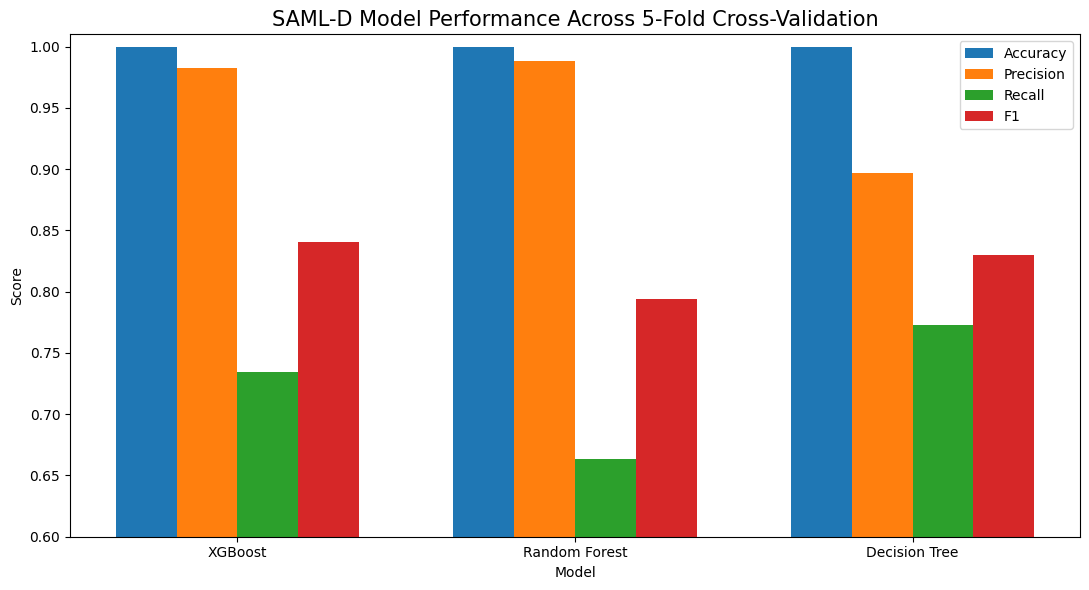

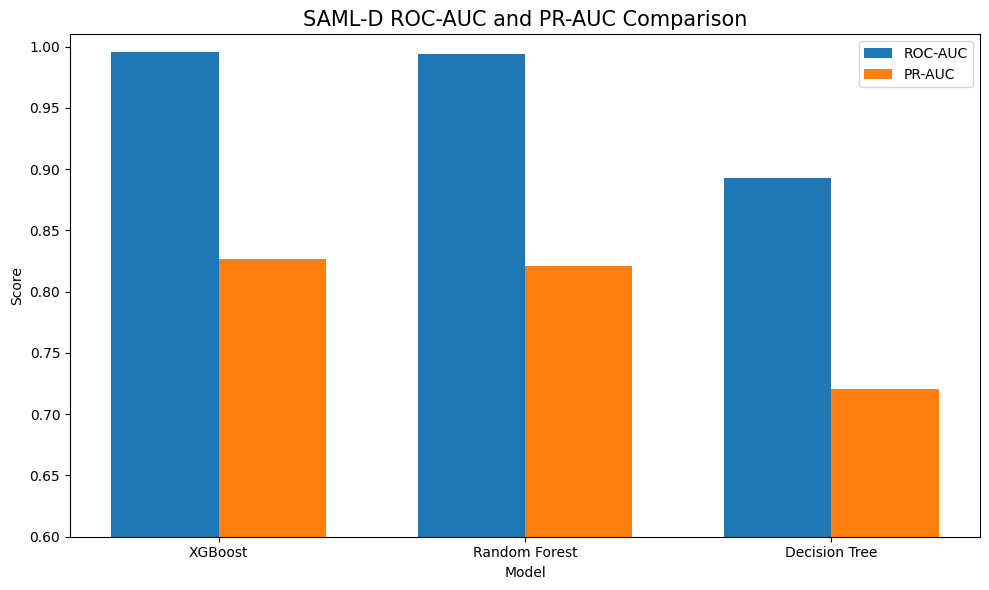

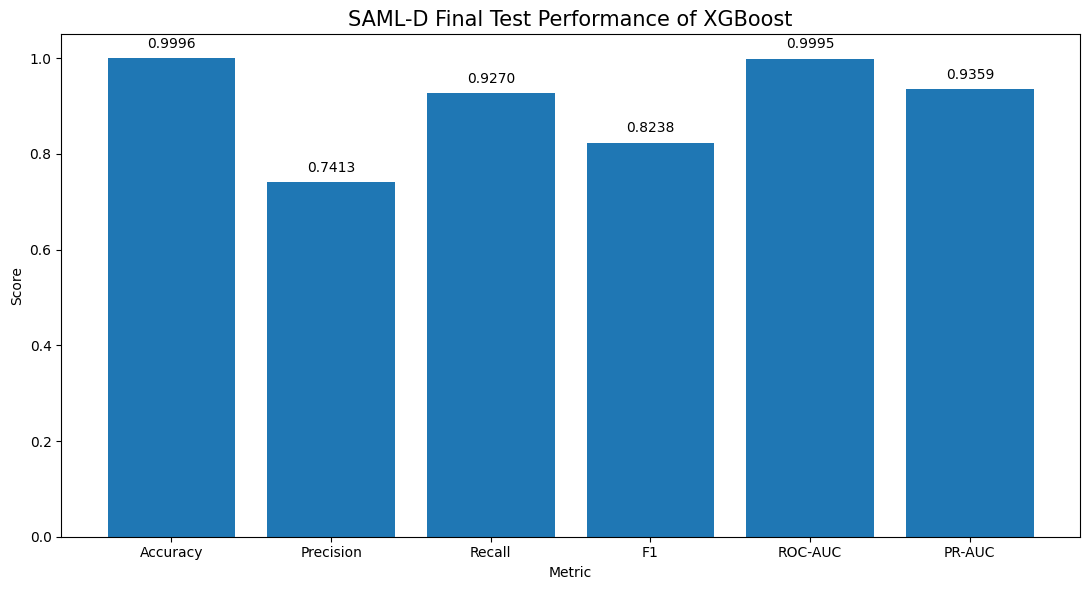

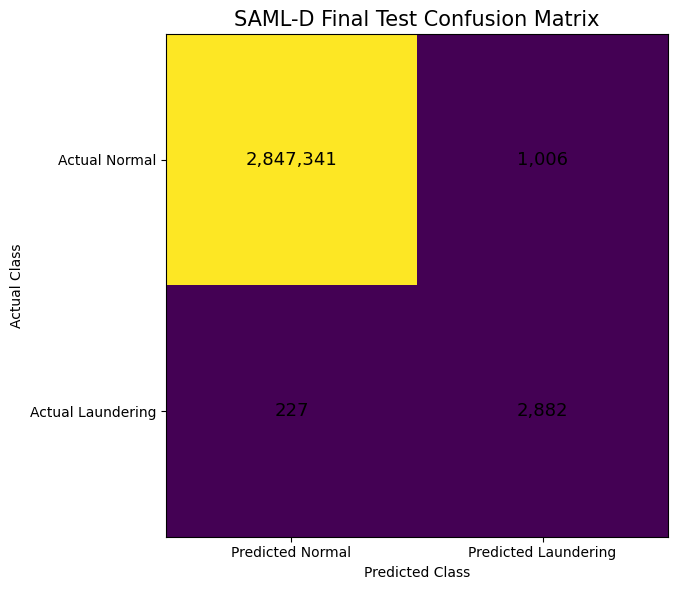

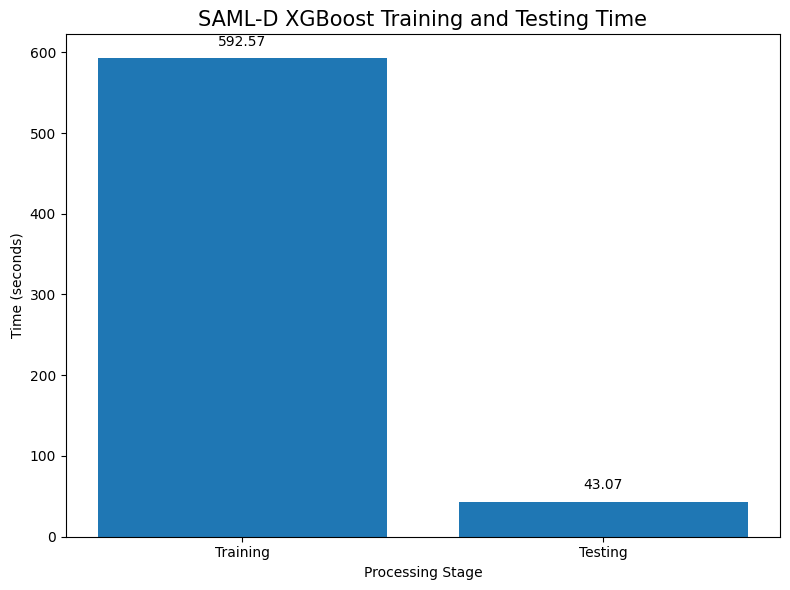

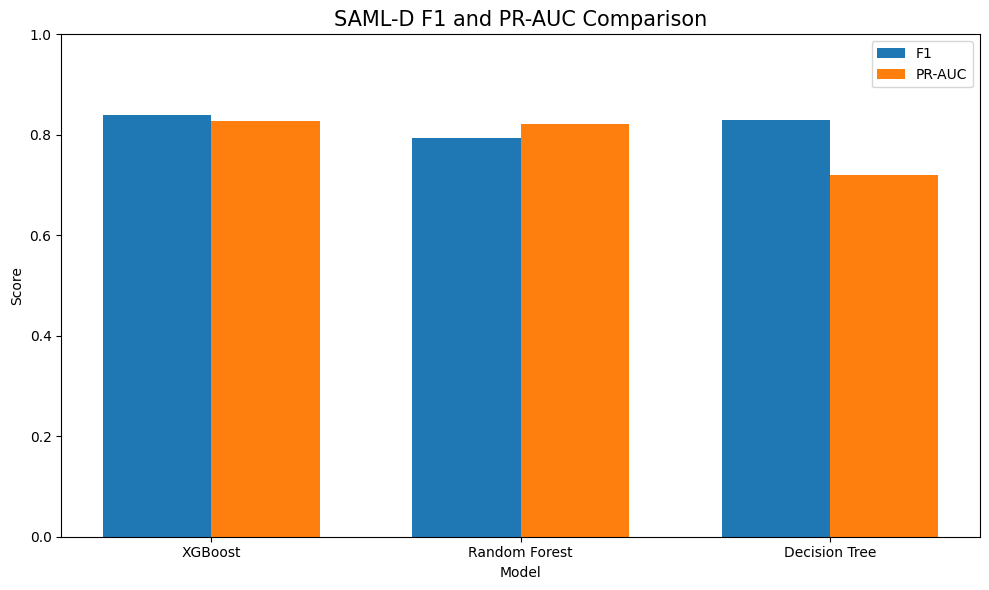


Report graphs and tables saved to:
/kaggle/working/samld_report_outputs

Files generated:
Figure_1_CV_Model_Performance.png
Figure_2_ROC_AUC_vs_PR_AUC.png
Figure_3_Final_Test_Performance.png
Figure_4_Confusion_Matrix.png
Figure_5_Training_vs_Testing_Time.png
Figure_6_F1_vs_PR_AUC.png
Table_1_CV_Model_Comparison.csv
Table_2_Final_Test_Performance.csv
Table_3_Confusion_Matrix.csv
Table_4_Classification_Report.csv
Table_5_Dataset_Summary.csv


In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_DIR = "/kaggle/working/samld_results"
REPORT_DIR = "/kaggle/working/samld_report_outputs"

os.makedirs(REPORT_DIR, exist_ok=True)

# ============================================================
# LOAD RESULTS
# ============================================================

cv = pd.read_csv(
    os.path.join(RESULTS_DIR, "samld_cv_results.csv")
)

test = pd.read_csv(
    os.path.join(RESULTS_DIR, "samld_final_test_results.csv")
)

cm = pd.read_csv(
    os.path.join(RESULTS_DIR, "samld_confusion_matrix.csv"),
    index_col=0
)

report = pd.read_csv(
    os.path.join(RESULTS_DIR, "samld_classification_report.csv"),
    index_col=0
)

# ============================================================
# TABLE 1 — CROSS-VALIDATION RESULTS
# ============================================================

cv_table = cv[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ]
].copy()

for col in cv_table.columns[1:]:
    cv_table[col] = cv_table[col].round(4)

cv_table.to_csv(
    os.path.join(
        REPORT_DIR,
        "Table_1_CV_Model_Comparison.csv"
    ),
    index=False
)

display(cv_table)


# ============================================================
# TABLE 2 — FINAL TEST RESULTS
# ============================================================

test_table = test[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "Training_Time",
        "Testing_Time"
    ]
].copy()

for col in test_table.columns[1:7]:
    test_table[col] = test_table[col].round(4)

test_table["Training_Time"] = test_table["Training_Time"].round(2)
test_table["Testing_Time"] = test_table["Testing_Time"].round(2)

test_table.to_csv(
    os.path.join(
        REPORT_DIR,
        "Table_2_Final_Test_Performance.csv"
    ),
    index=False
)

display(test_table)


# ============================================================
# TABLE 3 — CONFUSION MATRIX
# ============================================================

cm_table = cm.copy()

cm_table.to_csv(
    os.path.join(
        REPORT_DIR,
        "Table_3_Confusion_Matrix.csv"
    )
)

display(cm_table)


# ============================================================
# TABLE 4 — CLASSIFICATION REPORT
# ============================================================

report_table = report.copy()

report_table = report_table.round(4)

report_table.to_csv(
    os.path.join(
        REPORT_DIR,
        "Table_4_Classification_Report.csv"
    )
)

display(report_table)


# ============================================================
# TABLE 5 — DATASET SUMMARY
# ============================================================

dataset_summary = pd.DataFrame({
    "Measure": [
        "Total transactions",
        "Normal transactions",
        "Laundering transactions",
        "Laundering percentage",
        "Training transactions",
        "Testing transactions",
        "Training laundering rate",
        "Testing laundering rate"
    ],
    "Value": [
        9504852,
        9494979,
        9873,
        f"{9873 / 9504852 * 100:.4f}%",
        6653396,
        2851456,
        f"{0.001017 * 100:.4f}%",
        f"{0.001090 * 100:.4f}%"
    ]
})

dataset_summary.to_csv(
    os.path.join(
        REPORT_DIR,
        "Table_5_Dataset_Summary.csv"
    ),
    index=False
)

display(dataset_summary)


# ============================================================
# FIGURE 1 — MODEL PERFORMANCE
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1"
]

x = np.arange(len(cv["Model"]))
width = 0.18

fig, ax = plt.subplots(figsize=(11, 6))

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1.5) * width,
        cv[metric],
        width,
        label=metric
    )

ax.set_title(
    "SAML-D Model Performance Across 5-Fold Cross-Validation",
    fontsize=15
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(cv["Model"])

ax.set_ylim(0.6, 1.01)

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        REPORT_DIR,
        "Figure_1_CV_Model_Performance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# FIGURE 2 — ROC-AUC VS PR-AUC
# ============================================================

x = np.arange(len(cv["Model"]))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    cv["ROC-AUC"],
    width,
    label="ROC-AUC"
)

ax.bar(
    x + width / 2,
    cv["PR-AUC"],
    width,
    label="PR-AUC"
)

ax.set_title(
    "SAML-D ROC-AUC and PR-AUC Comparison",
    fontsize=15
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(cv["Model"])

ax.set_ylim(0.6, 1.01)

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        REPORT_DIR,
        "Figure_2_ROC_AUC_vs_PR_AUC.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# FIGURE 3 — FINAL TEST PERFORMANCE
# ============================================================

test_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC"
]

values = [
    float(test.iloc[0][metric])
    for metric in test_metrics
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    test_metrics,
    values
)

ax.set_title(
    "SAML-D Final Test Performance of XGBoost",
    fontsize=15
)

ax.set_xlabel("Metric")
ax.set_ylabel("Score")

ax.set_ylim(0, 1.05)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        REPORT_DIR,
        "Figure_3_Final_Test_Performance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# FIGURE 4 — CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    cm.values,
    interpolation="nearest"
)

ax.set_title(
    "SAML-D Final Test Confusion Matrix",
    fontsize=15
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_xticks(range(len(cm.columns)))
ax.set_yticks(range(len(cm.index)))

ax.set_xticklabels(cm.columns)
ax.set_yticklabels(cm.index)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            f"{cm.iloc[i, j]:,}",
            ha="center",
            va="center",
            fontsize=13
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        REPORT_DIR,
        "Figure_4_Confusion_Matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# FIGURE 5 — TRAINING VS TESTING TIME
# ============================================================

training_time = float(test.iloc[0]["Training_Time"])
testing_time = float(test.iloc[0]["Testing_Time"])

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(
    ["Training", "Testing"],
    [training_time, testing_time]
)

ax.set_title(
    "SAML-D XGBoost Training and Testing Time",
    fontsize=15
)

ax.set_xlabel("Processing Stage")
ax.set_ylabel("Time (seconds)")

for bar, value in zip(
    bars,
    [training_time, testing_time]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(training_time, testing_time) * 0.02,
        f"{value:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(
        REPORT_DIR,
        "Figure_5_Training_vs_Testing_Time.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# FIGURE 6 — F1 AND PR-AUC
# ============================================================

x = np.arange(len(cv["Model"]))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width / 2,
    cv["F1"],
    width,
    label="F1"
)

ax.bar(
    x + width / 2,
    cv["PR-AUC"],
    width,
    label="PR-AUC"
)

ax.set_title(
    "SAML-D F1 and PR-AUC Comparison",
    fontsize=15
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(cv["Model"])

ax.set_ylim(0, 1)

ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        REPORT_DIR,
        "Figure_6_F1_vs_PR_AUC.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# FINAL OUTPUT
# ============================================================

print("\nReport graphs and tables saved to:")
print(REPORT_DIR)

print("\nFiles generated:")

for file in sorted(os.listdir(REPORT_DIR)):
    print(file)

In [9]:
import shutil
from IPython.display import FileLink, display

REPORT_DIR = "/kaggle/working/samld_report_outputs"

ZIP_PATH = shutil.make_archive(
    "/kaggle/working/SAML_D_Report",
    "zip",
    REPORT_DIR
)

print("ZIP created:")
print(ZIP_PATH)

display(
    FileLink(
        ZIP_PATH,
        result_html_prefix="Download SAML-D Report Package: "
    )
)

ZIP created:
/kaggle/working/SAML_D_Report.zip


/kaggle/working/SAML_D_Report.zip